# Mask 更新測試 (3D 版)

把自訂的 n×n boolean mask（`False` = base color、`True` = highlight）轉成逐髮絲 (per-strand) mask，
再依髮絲的 3D 幾何更新 mask，最後存成 `coloring_by_strand` 的 per-strand template 交給 Blender 渲染。

演算法與工具都已整理成 library，這本 notebook 只負責呼叫與看結果：

| library | 內容 |
|---|---|
| [`update_contour`](../update_contour/README.md) | `ScalpGrid`（頭皮 grid / 切線基底 / 髮絲歸屬）、mask 轉換、3D 通量、majority vote、FM、3D active contour、trim |
| [`mask_analysis`](../mask_analysis/README.md) | 分析數值 (`scores`)、畫圖 (`plots`)、Blender 渲染 (`render`) |

邊緣訊號是每格 3D 柱體的**淨向外通量** ∮ v·n̂ dA（`update_contour.cal_grid_flux_3d`）：直接在 3D 局部座標
(t1, t2, normal) 上量髮絲單位流向的法向分量，不擬合、不求導；只有畫圖時才把流向投影到 2D。

In [1]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

HERE = "/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample"
PROJECT_ROOT = os.path.abspath(os.path.join(HERE, "..", "..", ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import highlighting.generate_from_3D_models.update_contour as uc
import highlighting.generate_from_3D_models.mask_analysis as ma
from highlighting.generate_from_3D_models.mask_analysis import plots, render
from highlighting.generate_from_3D_models.scalp_grid_volume_sample.hair_query import load_strands

plots.setup_cjk_font()

DATASET_ROOT = uc.default_dataset_path()   # <PROJECT_ROOT>/DiffLocks_Dataset/difflocks_dataset
HAIRSTYLE_DIR = os.path.join(DATASET_ROOT, "generated_hairstyles", "base_13_idx_94847")
STRANDS_NPZ = os.path.join(HAIRSTYLE_DIR, "full_strands.npz")
N = 32  # grid 解析度 (N x N)

## 1. 頭皮 grid 與髮絲

`ScalpGrid.from_dataset(N)` 一次建好：每格的 3D 位置 / 法向量、切線基底 (t1: +u, t2: +v)、柱體半寬 `half_size`、UV bin。
`strand_mask_grid[u, v, k]` = 第 k 根髮絲是否穿過格子 (u, v) 上方的柱體（有 CUDA 就走 GPU）。

索引慣例：`grid.*` / `strand_mask_grid` 是 `(u_idx, v_idx)` 排列；所有 N×N mask / 分數圖是 `(row, col)` 排列
（row 0 = 高 v 端，跟 template PNG 一致），`uc.uv_to_rc` 負責轉換。

有效 (落在頭皮上) 的 cell 數: 730 / 1024, half_size = 0.00599
strand_positions: (96821, 256, 3)


100%|██████████| 46/46 [00:06<00:00,  7.58it/s]


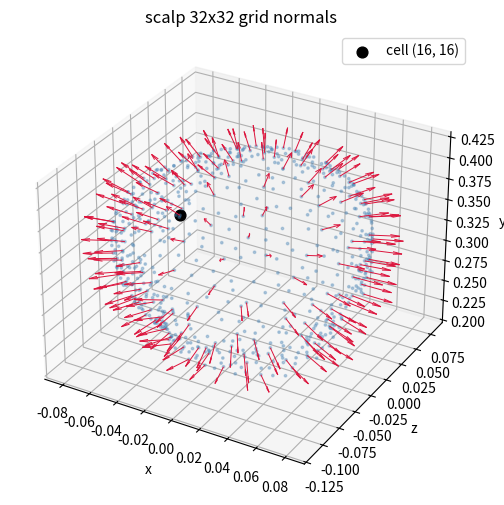

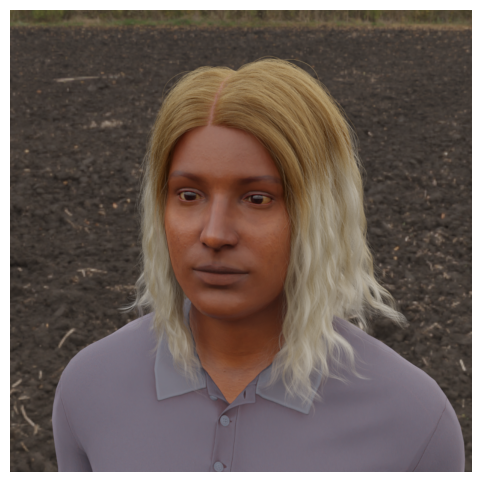

In [2]:
grid = uc.ScalpGrid.from_dataset(N)
g = grid.arrays()   # grid_pos, grid_normal, grid_valid, half_size, grid_t1, grid_t2
print(f"有效 (落在頭皮上) 的 cell 數: {grid.grid_valid.sum()} / {grid.grid_valid.size}, half_size = {grid.half_size:.5f}")

strand_positions, root_uv, root_normal = load_strands(STRANDS_NPZ)
print("strand_positions:", strand_positions.shape)   # (S, P, 3)

row_idx, col_idx = grid.root_rowcol(root_uv)           # 每根髮絲髮根所在的 (row, col)
strands_mask_grid = grid.strand_mask_grid(strand_positions)   # (N, N, S) bool

plots.plot_grid_normals_3d(g["grid_pos"], g["grid_normal"], g["grid_valid"], cell=(N // 2, N // 2))
plt.figure(figsize=(6, 6)); plt.imshow(plt.imread(os.path.join(HAIRSTYLE_DIR, "rgb.png"))); plt.axis("off");

## 2. 自訂 N×N mask -> 逐髮絲 mask

每根髮絲的 mask = 它髮根所在格子的值（`grid_mask_to_strand_mask`）。

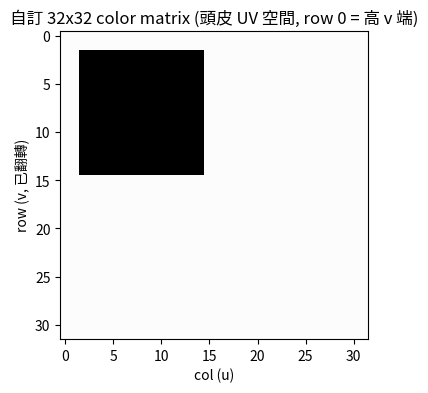

highlight 髮絲數: 18798 / 96821


In [3]:
BASE_COLOR = np.array([0.99, 0.99, 0.99])
HIGHLIGHT_COLOR = np.array([0.0, 0.0, 0.0])

mask_matrix = np.zeros((N, N), dtype=bool)
mask_matrix[2:15, 2:15] = True

plots.show_color_matrix(uc.mask_to_rgb(mask_matrix, BASE_COLOR, HIGHLIGHT_COLOR))
base_strand_mask = uc.grid_mask_to_strand_mask(mask_matrix, row_idx, col_idx)   # (S,) bool
print("highlight 髮絲數:", int(base_strand_mask.sum()), "/", base_strand_mask.size)

## 3. 勾邊測試：3D 淨向外通量 |flux|

通量只跟髮絲幾何有關（跟 mask 無關），整張圖算一次，後面的 active contour / 疊圖共用。

100%|██████████| 1024/1024 [00:04<00:00, 211.47it/s]


average |flux| = 0.03586699
edge cells = 43 / 730 valid cells


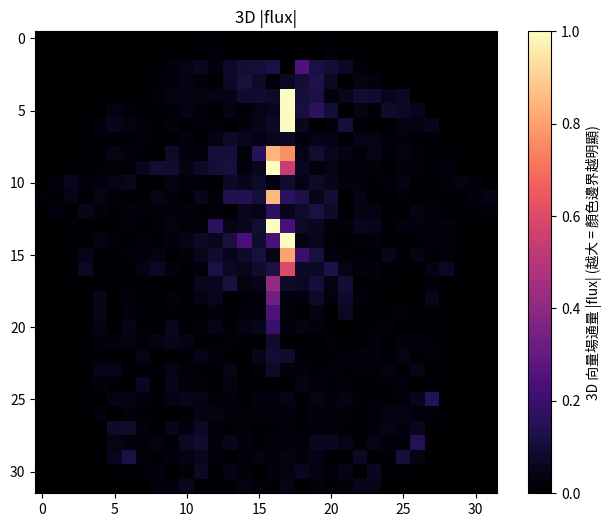

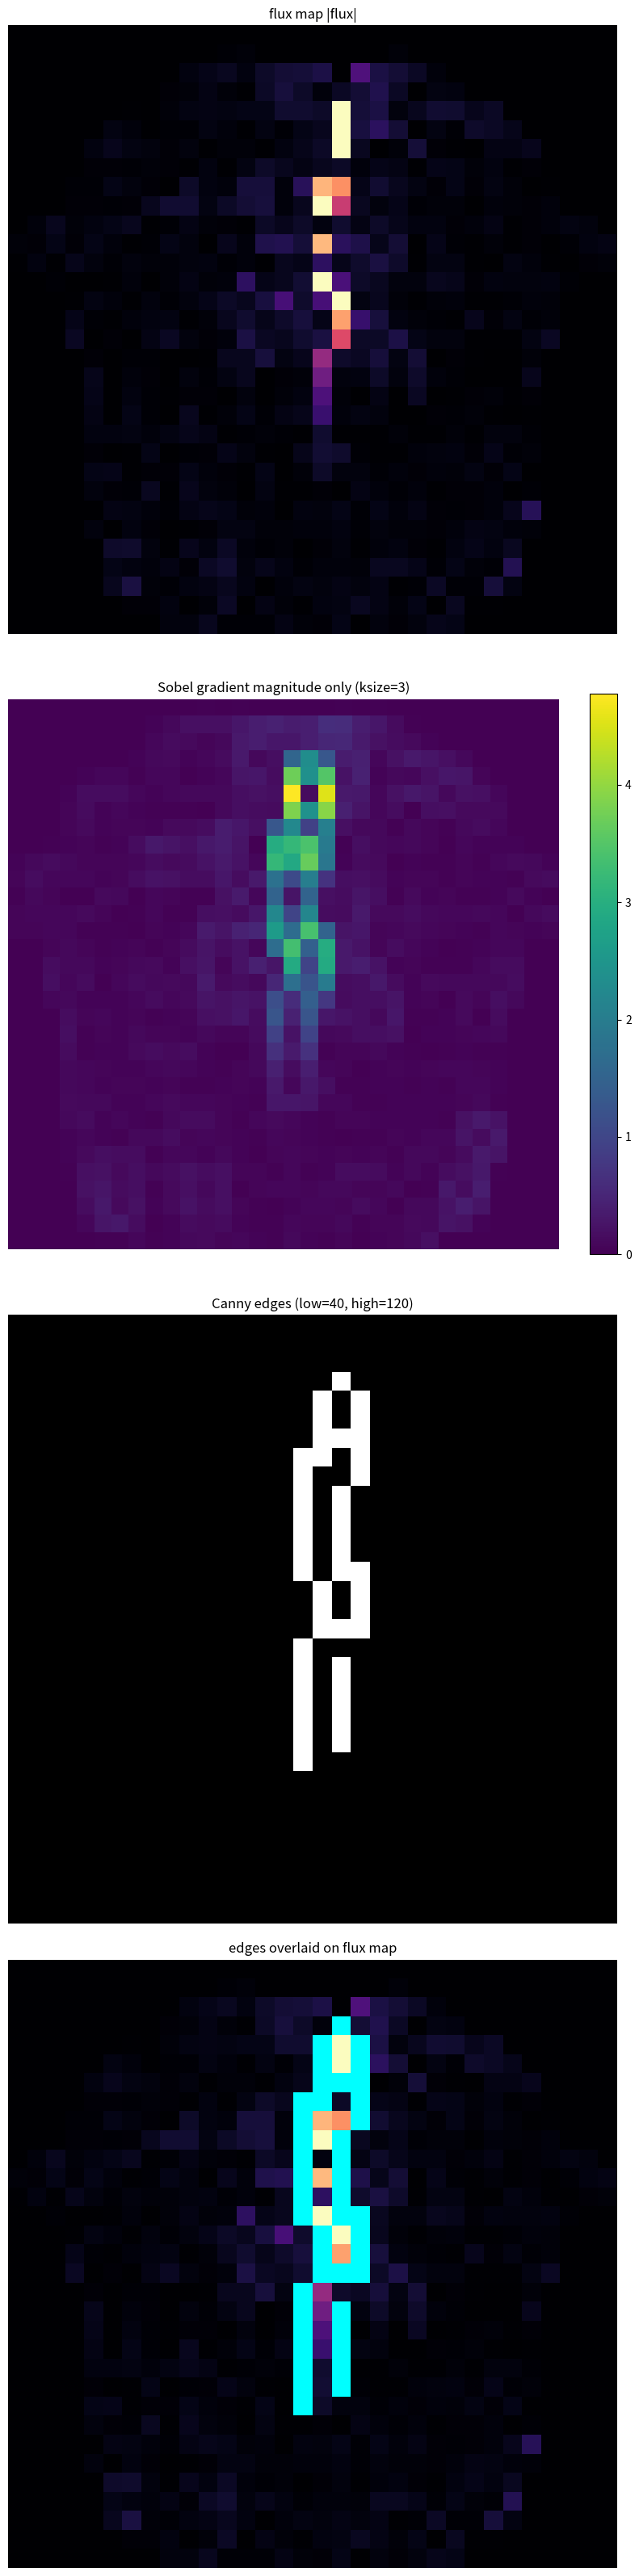

In [4]:
flux3d, flux_ok = uc.cal_grid_flux_3d(
    strand_positions, g["grid_pos"], g["grid_normal"], g["grid_valid"], g["half_size"], strands_mask_grid,
    grid_t1=g["grid_t1"], grid_t2=g["grid_t2"],
)
grid_score = ma.edge_score_from_flux(flux3d)
print("average |flux| =", grid_score.mean())

plots.plot_score_map(grid_score, title="3D |flux|")
edge_result = ma.detect_flux_edges(grid_score, g["grid_valid"], canny_low=40, canny_high=120)
print(f"edge cells = {edge_result['edges'].sum()} / {edge_result['valid_rc'].sum()} valid cells")
plots.plot_flux_edges(grid_score, edge_result, title_suffix=" (low=40, high=120)");

100%|██████████| 1024/1024 [00:04<00:00, 227.17it/s]


strand_pts2d: (16679000, 2)


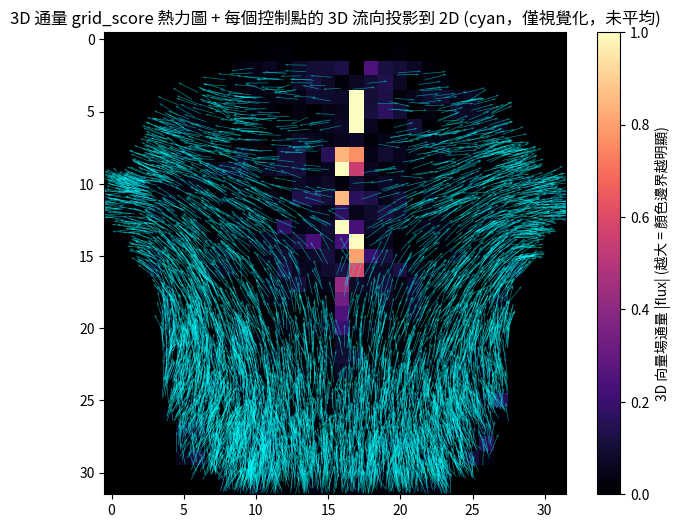

In [7]:
# 每根髮絲每個控制點的 3D 流向投影到 2D (僅視覺化，未平均)
strand_pts2d, strand_vec2d = ma.compute_strand_vectors_2d(
    strand_positions, g["grid_pos"], g["grid_normal"], g["grid_valid"], g["half_size"], strands_mask_grid,
    grid_t1=g["grid_t1"], grid_t2=g["grid_t2"],
)
print("strand_pts2d:", strand_pts2d.shape)
plots.plot_score_with_flow(grid_score, strand_pts2d, strand_vec2d, max_arrows=6000);

## 4. 更新 mask

預設用 FM (Fiduccia-Mattheyses, clique 目標)；`iter_strand_masks[0]` 是初始 mask，之後每個元素是一個 pass 的結果。
另一種做法 (majority vote，原 `update_color`) 放在註解裡。

自然邊界 0 格


active contour: 100%|██████████| 1/1 [00:00<00:00, 36.14it/s]


被翻轉的 cell: 43
被翻轉的 cell: 16
被翻轉的 cell: 12


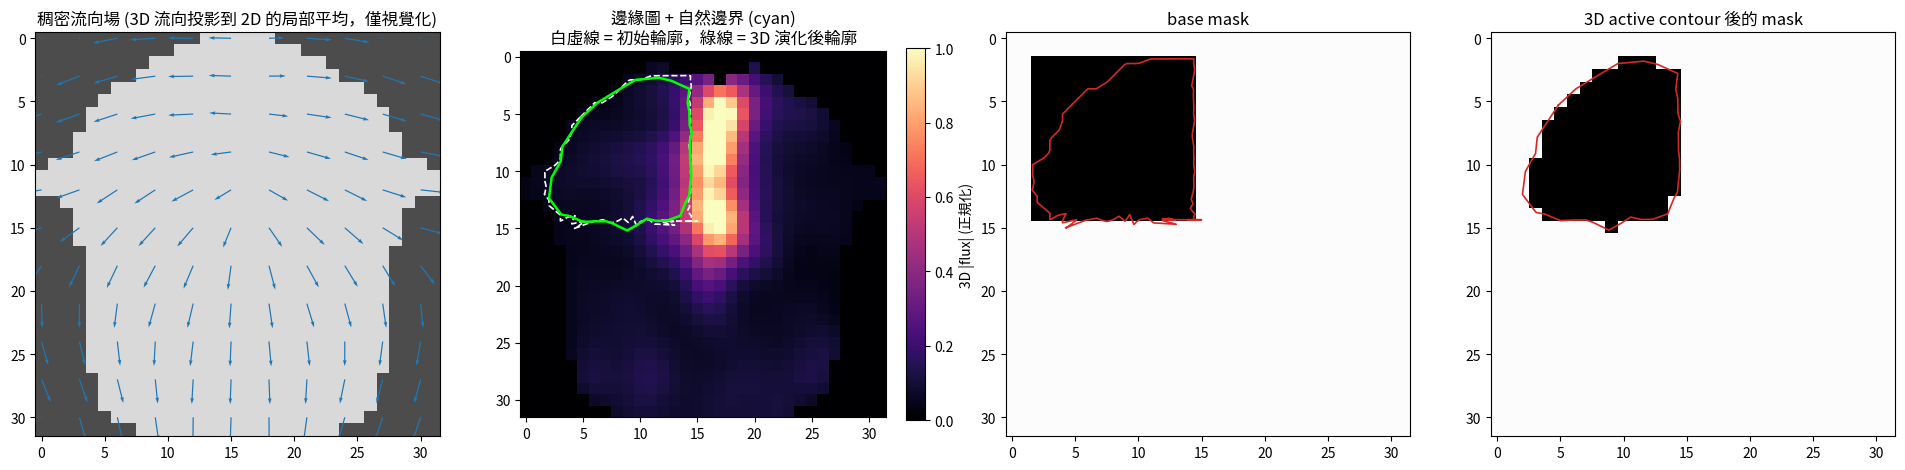

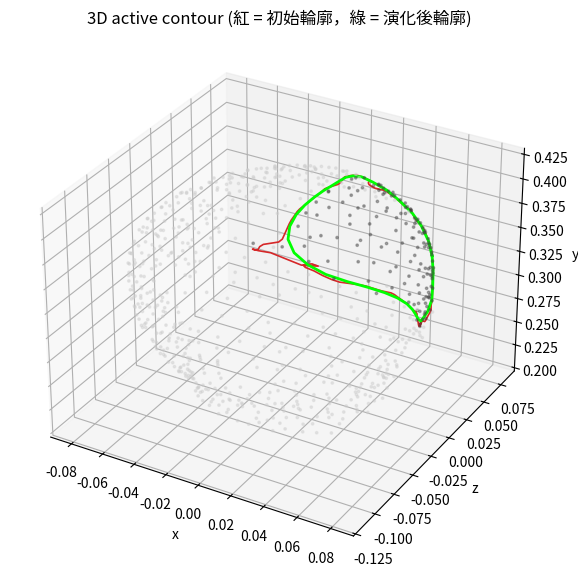

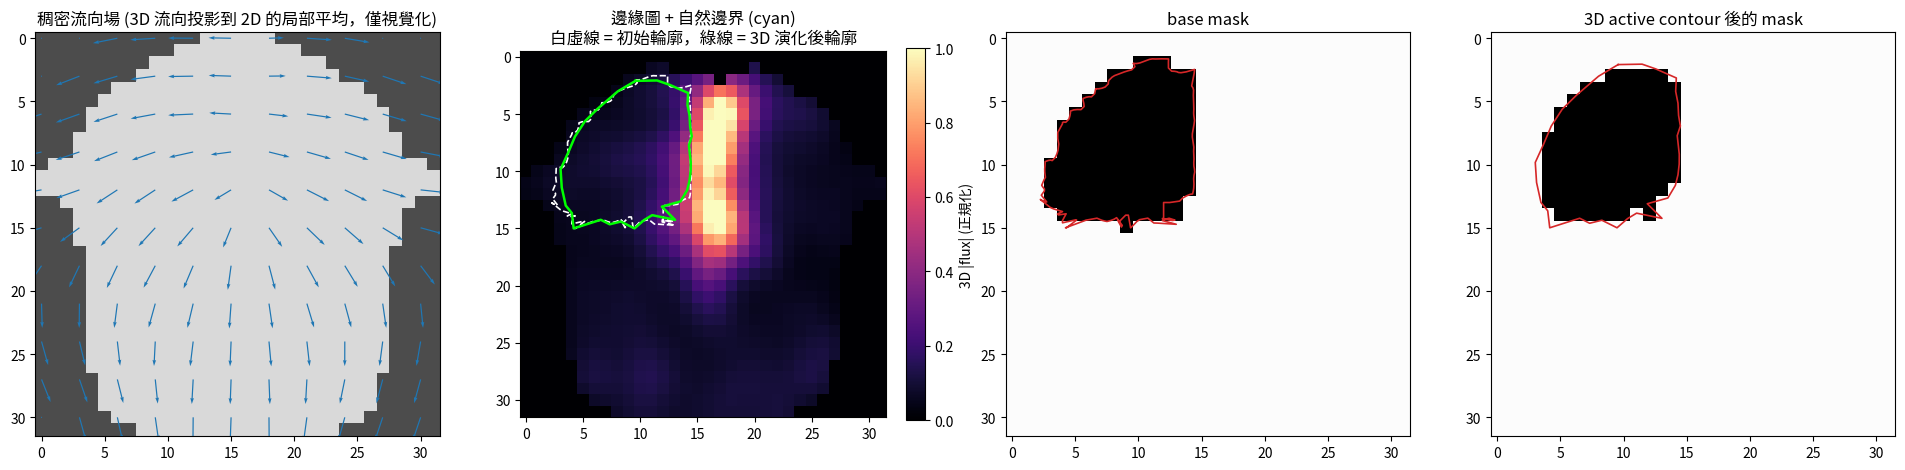

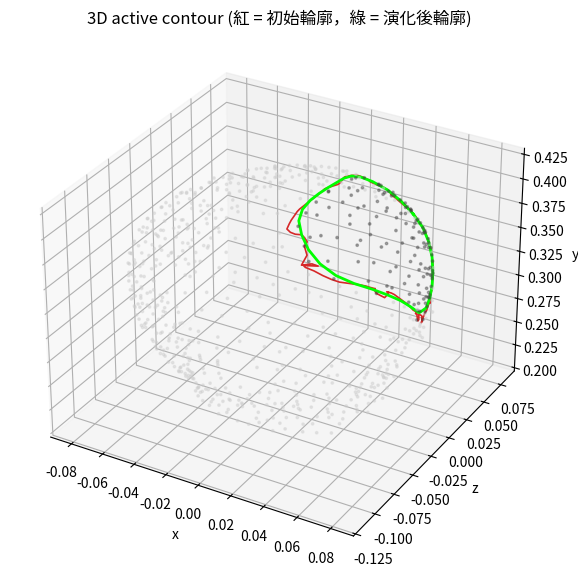

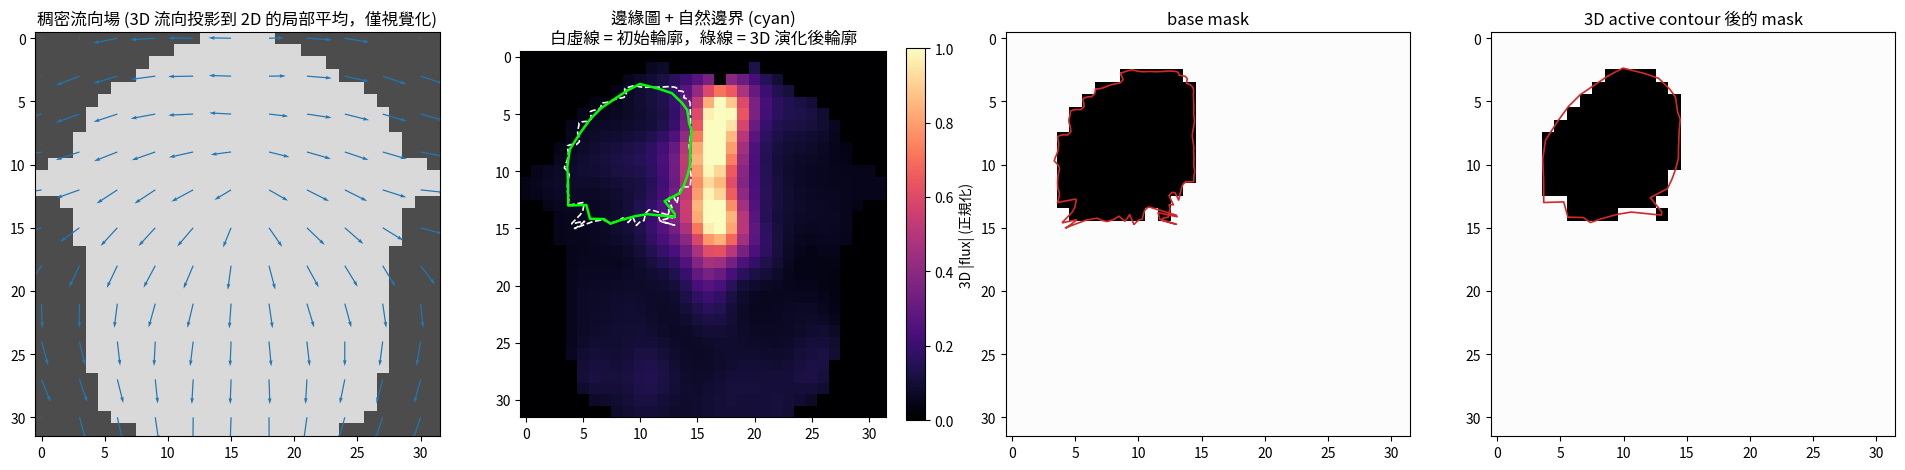

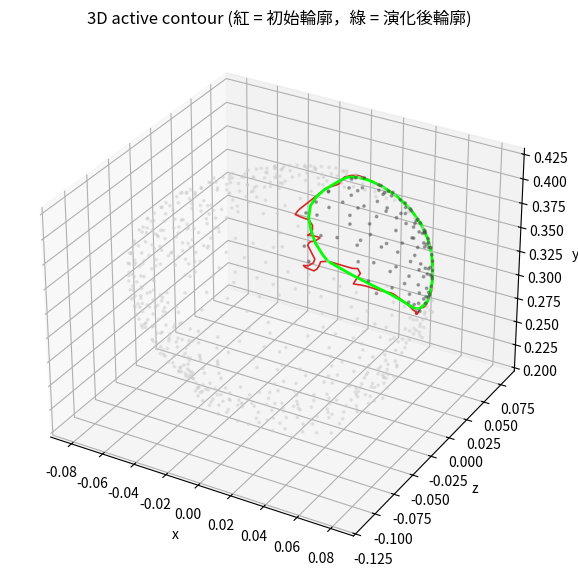

In [6]:
natural_boundary = uc.prepare_natural_boundary(flux3d, flux_ok, g["grid_pos"], g["grid_valid"], edge_smooth=1.5)
print(f"自然邊界 {int(natural_boundary.mask.sum())} 格")
rounds = uc.update_contour_active(
    mask_matrix, natural_boundary, g["half_size"], snap_radius=8, n_rounds=3,
    alpha=0.2, beta=0.4, kappa=1.0, anchor=0.5, n_iter=100,
)
flow = ma.rasterize_flow_field(strand_pts2d, strand_vec2d, N, sigma=1.5)[:2]
for r in rounds:
    print("被翻轉的 cell:", int((r["mask"] != r["init_mask"]).sum()))
    plots.plot_active_contour_2d(r, natural_boundary, grid.valid_rc, flow=flow)
    plots.plot_active_contour_3d(r, natural_boundary, grid.valid_rc)
iter_strand_masks = [base_strand_mask, uc.grid_mask_to_strand_mask(rounds[-1]["mask"], row_idx, col_idx)]
n_iter = 1

## 5. 結果分析

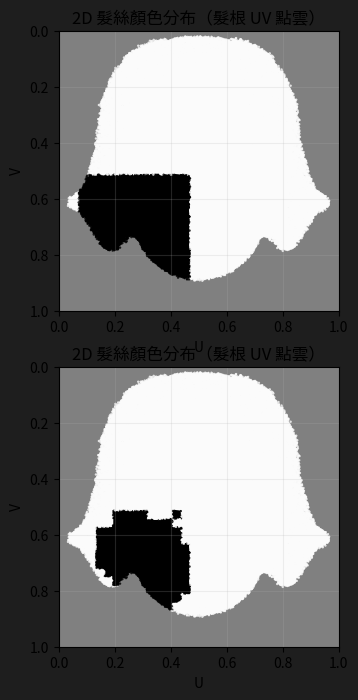

In [8]:
# 髮根 UV 點雲，顏色 = 每輪的 strand mask
plots.plot_strand_uv_iterations(root_uv, iter_strand_masks, BASE_COLOR, HIGHLIGHT_COLOR);

100%|██████████| 1024/1024 [00:04<00:00, 254.06it/s]


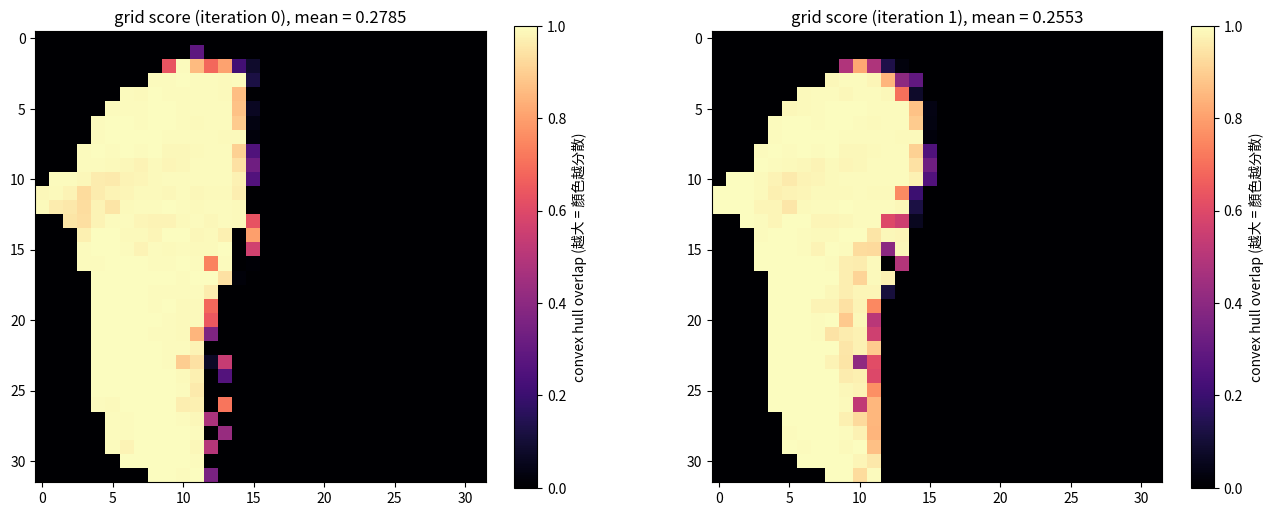

In [9]:
# 每格 convex hull overlap (越大 = 兩種顏色越混)
grid_scores = [
    ma.cal_grid_score(strand_positions, g["grid_pos"], g["grid_normal"], g["grid_valid"], m, g["half_size"],
                      strands_mask_grid, grid_t1=g["grid_t1"], grid_t2=g["grid_t2"])
    for m in iter_strand_masks
]
plots.plot_grid_score_iterations(grid_scores);

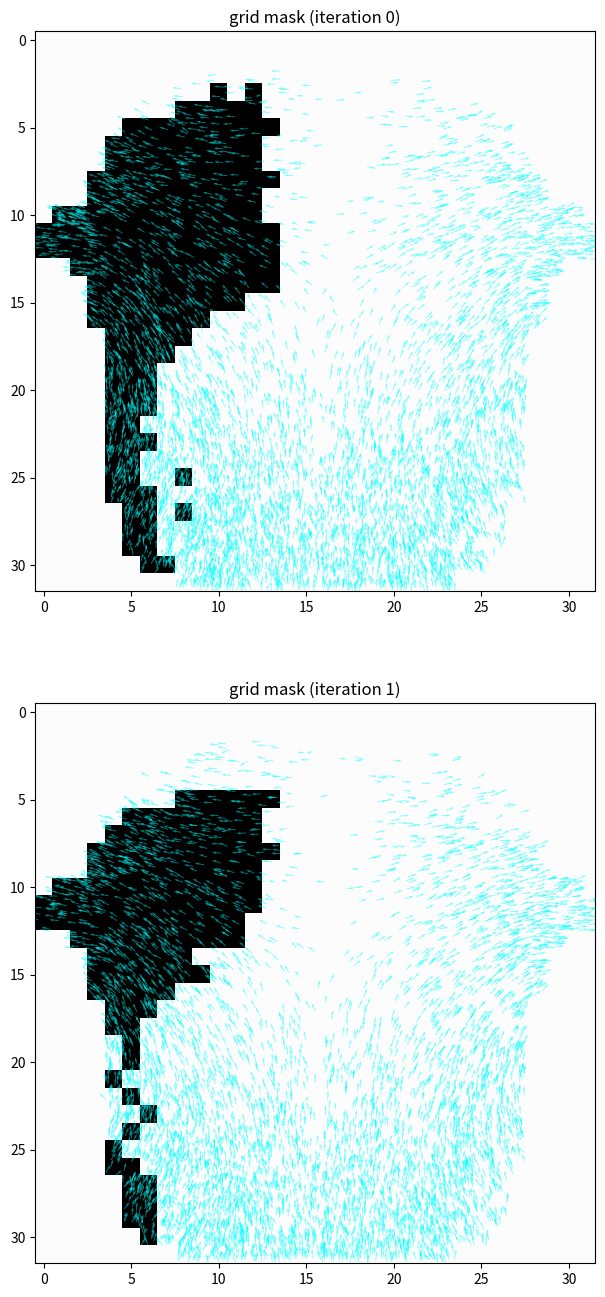

In [10]:
# 每格的 mask 眾數 (2D 結果)，疊上髮絲流向；edge_score=grid_score 可再疊通量點
show_direction_vec = True
show_edge_detect_score = False

grid_masks = [uc.strand_mask_to_grid_mask(m, strands_mask_grid) for m in iter_strand_masks]
plots.plot_grid_mask_iterations(
    grid_masks, BASE_COLOR, HIGHLIGHT_COLOR,
    pts2d=strand_pts2d if show_direction_vec else None,
    vec2d=strand_vec2d if show_direction_vec else None,
    edge_score=grid_score if show_edge_detect_score else None,
);

## 7. Trim 與 Blender 渲染

`trim`：每輪挑出跟鄰居衝突最嚴重的 `max_cut` 根髮絲，渲染 `*_trimmed` 版本時整根不畫。
`render.render_iterations` 把 `iter_strand_masks[0]` 存到 `output/base_3D`、第 i 輪存到 `output/iter_3D_<i>`
（外加 `iter_3D_<i>_trimmed`），template 寫到 `coloring_by_strand/{base,median}_templates_3D`。

In [11]:
incidence = uc.build_cell_incidence(strands_mask_grid)
trimmed_masks = [uc.trim(m, incidence, max_cut=1000) for m in iter_strand_masks]

In [ ]:
RUN_RENDER = True

if RUN_RENDER:
    render.render_iterations(
        iter_strand_masks, out_root=os.path.join(HERE, "output"),
        root_uv=root_uv, strands_npz=STRANDS_NPZ, dataset_path=DATASET_ROOT, grid_size=N,
        trim_masks=trimmed_masks, base_color=BASE_COLOR, highlight_color=HIGHLIGHT_COLOR,
        source="mask_updating_test_3D.ipynb",
    )